### Environment Setup and Library Imports
Imports required data manipulation, visualization, and machine learning libraries, including `pandas`, `numpy`, `matplotlib`, `seaborn`, and key `scikit-learn` clustering tools (`KMeans`, `AgglomerativeClustering`, and evaluation metrics).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

print("All toolboxes loaded successfully!")

All toolboxes loaded successfully!


### Verify Local Dataset Directory Contents
Sets the root directory path (`folder_path`) for the household dataset and lists all available section CSV files to ensure required files exist.

In [2]:
import os

folder_path = r"C:\Users\Sarah\Household dataset"

# List all files in your folder
files = os.listdir(folder_path)
print("Files in folder:")
for f in files:
    print("-", f)

Files in folder:
- sect07_12month.csv
- sect07_30day.csv
- sect07_7day.csv
- sect10_assets.csv
- sect11a_credit.csv
- sect11b_credit.csv
- sect11c_credit.csv
- sect12a_beta.csv
- sect12a_safety.csv
- sect12b_safety.csv
- sect13_income.csv
- sect14_housing.csv
- sect16_shocks.csv
- sect17_crime_security.csv
- sect18_agriculture.csv
- sect19a_land.csv
- sect19b_land.csv
- sect1_roster.csv
- sect2_education.csv
- sect3_health.csv
- sect4a1_labour.csv
- sect4a2_labour.csv
- sect5_remittances.csv
- sect6a_meals_outside.csv
- sect6b_food_cons.csv
- sect6c_aggregate_food_1.csv
- sect6c_aggregate_food_2.csv
- sect6c_aggregate_food_3.csv
- sect8_food_security.csv
- sect9a_enterprise.csv
- sect9b_enterprise.csv
- sect9c_enterprise.csv
- sect9d_enterprise.csv
- secta_cover.csv
- sect_aux.csv
- sect_result.csv
- totcons.csv


### Initial Data Loading
Loads key NLSS survey modules into DataFrames:
- `totcons.csv` (Welfare / Expenditure)
- `sect14_housing.csv` (Housing characteristics)
- `sect1_roster.csv` & `sect2_education.csv` (Demographics and Education)
- `sect10_assets.csv` (Household Assets)

In [3]:

folder_path = r"C:\Users\Sarah\Household dataset"

# 1. Load Total Consumption / Expenditure (Main Welfare Metric)
totcons = pd.read_csv(os.path.join(folder_path, "totcons.csv"))

# 2. Load Housing & Utilities (Electricity, Water, Rooms)
housing = pd.read_csv(
    os.path.join(folder_path, "sect14_housing.csv"), low_memory=False
)

# 3. Load Household Roster (Education of Household Head)
roster = pd.read_csv(os.path.join(folder_path, "sect1_roster.csv"))
education = pd.read_csv(
    os.path.join(folder_path, "sect2_education.csv"), low_memory=False
)

# 4. Load Assets
assets = pd.read_csv(os.path.join(folder_path, "sect10_assets.csv"))

print("Files loaded successfully! Ready to merge.")

Files loaded successfully! Ready to merge.


### Data Merging and Household Level Aggregation
Combines welfare data with housing characteristics, counts total assets per household, extracts the education level of the household head (`s01q03 == 1`), and merges everything into a unified dataset (`df_merged`).

In [4]:
# 1. Start with total consumption
df_merged = totcons.copy()

# 2. Merge housing characteristics
df_merged = pd.merge(df_merged, housing, on="hhid", how="left")

# 3. Aggregate assets count per household and merge
assets_count = assets.groupby("hhid").size().reset_index(name="asset_count")
df_merged = pd.merge(df_merged, assets_count, on="hhid", how="left")

# 4. Extract household head education level and merge
heads = roster[roster['s01q03'] == 1]  # Filter for household head
head_edu = pd.merge(heads, education, on=["hhid", "indiv"], how="left")
df_merged = pd.merge(df_merged, head_edu[['hhid', 's02q04']], on="hhid", how="left")

# Clean missing values filled during merge
df_merged['asset_count'] = df_merged['asset_count'].fillna(0)

print("Merged Data Shape:", df_merged.shape)
df_merged.head()

Merged Data Shape: (22110, 185)


,hhid,sector_x,zone_x,state_x,lga_x,ea_x,month_of_interview,year_of_interview,hhsize,wt_final,...,s14q42_os,s14q43,s14q44,s14q45,s14q46,s14q46_os,s14q47a,s14q47b,asset_count,s02q04
0,111074,1,4,1,111,1384,10,2018,3,2930.107345,...,NaN,2.0,2.0,NaN,2,NaN,100.0,3.0,36,1.0
1,111077,1,4,1,111,1384,10,2018,3,2930.107345,...,NaN,3.0,1.0,12.0,4,NaN,NaN,NaN,36,2.0
2,111075,1,4,1,111,1384,10,2018,7,2930.107345,...,NaN,1.0,2.0,NaN,5,NaN,NaN,NaN,36,1.0
3,111079,1,4,1,111,1384,10,2018,3,2930.107345,...,NaN,2.0,1.0,5.0,2,NaN,400.0,4.0,36,1.0
4,111071,1,4,1,111,1384,10,2018,8,2930.107345,...,NaN,2.0,1.0,99.0,2,NaN,600.0,4.0,36,2.0


### Raw Asset Data Structure Inspection
Loads `sect10_assets.csv` directly to examine column structure and verify asset ownership flags (`s10q01`).

In [5]:
folder_path = r"C:\Users\Sarah\Household dataset"

# Use folder_path instead of '.'
assets_path = os.path.join(folder_path, "sect10_assets.csv")
raw_assets = pd.read_csv(assets_path)

print("--- Raw Assets Columns ---")
print(raw_assets.columns.tolist())

print("\n--- Sample Asset Rows ---")
print(raw_assets.head(3))

--- Raw Assets Columns ---
['hhid', 'sector', 'zone', 'state', 'lga', 'ea', 'asset_cd', 's10q01', 's10q02', 's10q03', 's10q04__0', 's10q04__1', 's10q04__2', 's10q04__3', 's10q04__4', 's10q04__5', 's10q04__6', 's10q04__7', 's10q04__8', 's10q04__9', 's10q04__10', 's10q04__11', 's10q04__12', 's10q04__13', 's10q04__14']

--- Sample Asset Rows ---
     hhid  sector  zone  state  lga   ea  asset_cd  s10q01  s10q02  s10q03  \
0  101001       1     4      1  101  186       301     1.0     1.0     1.0   
1  101001       1     4      1  101  186       302     2.0     NaN     NaN   
2  101001       1     4      1  101  186       303     1.0     1.0     1.0   

   ...  s10q04__5  s10q04__6  s10q04__7  s10q04__8  s10q04__9  s10q04__10  \
0  ...        NaN        NaN        NaN        NaN        NaN         NaN   
1  ...        NaN        NaN        NaN        NaN        NaN         NaN   
2  ...        NaN        NaN        NaN        NaN        NaN         NaN   

   s10q04__11  s10q04__12  s10q04

### Asset Ownership Aggregation
Filters `sect10_assets.csv` specifically for confirmed owned assets (`s10q01 == 1.0`), re-aggregates counts per household (`hhid`), and fills non-owning households with `0`.

In [6]:
folder_path = r"C:\Users\Sarah\Household dataset"
assets_path = os.path.join(folder_path, "sect10_assets.csv")

# 1. Load assets file using assets_path
raw_assets = pd.read_csv(assets_path)

# 2. Filter for rows where the household actually owns the asset (s10q01 == 1.0)
owned_assets = raw_assets[raw_assets["s10q01"] == 1.0]

# 3. Aggregate count of owned assets per household (hhid)
assets_per_hh = (
    owned_assets.groupby("hhid")["asset_cd"].count().reset_index()
)
assets_per_hh.rename(columns={"asset_cd": "asset_count"}, inplace=True)

# 4. Merge back with unique household IDs to assign 0 assets to households owning none
all_hhids = raw_assets[["hhid"]].drop_duplicates()
assets_clean = pd.merge(all_hhids, assets_per_hh, on="hhid", how="left").fillna(
    {"asset_count": 0}
)

# Verify new summary statistics
print("--- Corrected Asset Count Summary Statistics ---")
print(assets_clean["asset_count"].describe())

print("\n--- Corrected Unique Values Count ---")
print(assets_clean["asset_count"].nunique())

--- Corrected Asset Count Summary Statistics ---
count    22126.000000
mean         8.375712
std          4.844566
min          0.000000
25%          5.000000
50%          7.000000
75%         12.000000
max         30.000000
Name: asset_count, dtype: float64

--- Corrected Unique Values Count ---
31


### Feature Engineering – Log Transformation of Expenditure
Merges corrected asset counts into the main DataFrame and applies a logarithmic transformation (`log1p`) to per-capita expenditure (`totcons_pc`) to reduce right-skewness.

In [7]:

# 1. Merge corrected asset count into your analytical dataframe (df_merged)
# Replace 'df_merged' with your main household dataframe variable if different
df_clean = pd.merge(df_merged.drop(columns=['asset_count'], errors='ignore'), 
                    assets_clean, 
                    on='hhid', 
                    how='inner')

# 2. Apply Log Transformation to Expenditure
df_clean['log_totcons_pc'] = np.log1p(df_clean['totcons_pc'])

# 3. Inspect skewness before and after transformation
print("--- Expenditure Skewness Comparison ---")
print("Raw totcons_pc Skewness:    ", df_clean['totcons_pc'].skew())
print("Log totcons_pc Skewness:    ", df_clean['log_totcons_pc'].skew())

# 4. View summary statistics of the log-transformed variable
print("\n--- Log Expenditure Summary ---")
print(df_clean['log_totcons_pc'].describe())

--- Expenditure Skewness Comparison ---
Raw totcons_pc Skewness:     17.62573671139472
Log totcons_pc Skewness:     0.1968679775639756

--- Log Expenditure Summary ---
count    22110.000000
mean        12.041598
std          0.694122
min          9.691579
25%         11.561161
50%         12.022576
75%         12.493661
max         16.509447
Name: log_totcons_pc, dtype: float64


### Feature Matrix Preparation and Normalization
Prepares the target clustering features, handles missing values, and normalizes feature vectors to a $[0, 1]$ scale via `MinMaxScaler`.

In [8]:
# 1. Select key columns for clustering
feature_cols = ['totcons_pc', 'hhsize', 'asset_count', 's02q04']

# 2. Drop rows with missing values in these columns
df_clustering = df_merged[feature_cols].copy().dropna()

# 3. Scale all features to a 0-1 range (MinMax Normalization)
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df_clustering)

print("Original data size:", df_merged.shape[0])
print("Cleaned data size:", df_clustering.shape[0])
print("Scaled array shape:", X_scaled.shape)


Original data size: 22110
Cleaned data size: 22110
Scaled array shape: (22110, 4)


### Feature Extraction – Housing, Utilities, and Health Access
Loads Section 14 (Housing) and Section 3 (Health) to construct additional indicators: `electricity_access` (grid/generator) and `improved_sanitation` (flush/improved toilet).

In [9]:


# --- 1. EXTRACT HOUSING & UTILITIES (Section 14) ---
df_housing = pd.read_csv(
    os.path.join(folder_path, "sect14_housing.csv"), low_memory=False
)
# Electricity Access: check your column name (e.g., s14q12 or similar)
df_housing["electricity_access"] = df_housing["s14q12"].apply(
    lambda x: 1.0 if x in [1, 2] else 0.0
)

# Improved Sanitation
df_housing["improved_sanitation"] = df_housing["s14q09"].apply(
    lambda x: 1.0 if x in [1, 2, 3] else 0.0
)

# Keep relevant columns per household
housing_clean = df_housing[
    ["hhid", "electricity_access", "improved_sanitation"]
].drop_duplicates("hhid")


# --- 2. EXTRACT HEALTHCARE ACCESS (Section 3) ---
df_health = pd.read_csv(os.path.join(folder_path, "sect3_health.csv"), low_memory=False)

# Process health data using folder_path...

### Cluster Diagnostics Evaluation Loop ($k=2$ to $k=6$)
Evaluates K-Means clustering performance across various cluster counts ($k=2$ through $k=6$) by computing silhouette scores and plotting Elbow and Silhouette curves side-by-side.

k = 2 | 7D Silhouette Score: 0.9128
k = 3 | 7D Silhouette Score: 0.7643
k = 4 | 7D Silhouette Score: 0.5666
k = 5 | 7D Silhouette Score: 0.5514
k = 6 | 7D Silhouette Score: 0.5506


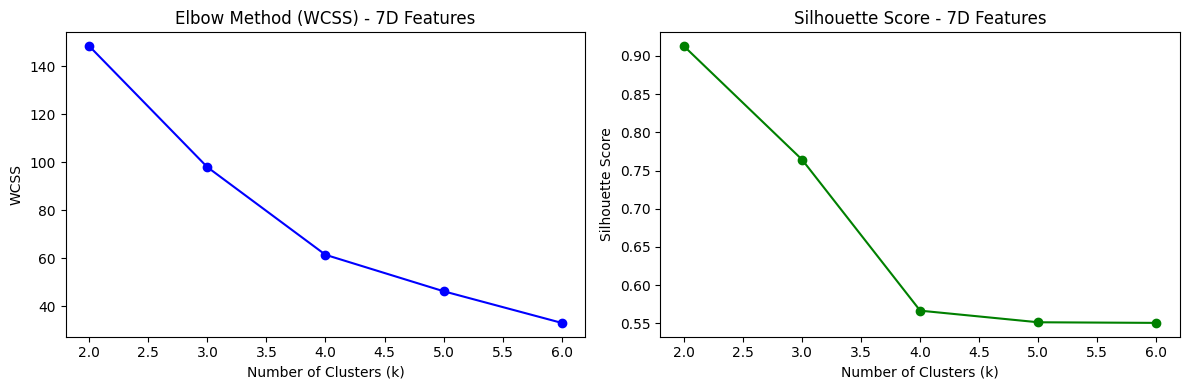

In [10]:
# Test cluster numbers from 2 to 6 on 7D scaled features
k_values = range(2, 7)
wcss = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    wcss.append(kmeans.inertia_)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"k = {k} | 7D Silhouette Score: {score:.4f}")

# Plot Elbow and Silhouette curves for 7D feature space
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(k_values, wcss, marker="o", color="b")
ax[0].set_title("Elbow Method (WCSS) - 7D Features")
ax[0].set_xlabel("Number of Clusters (k)")
ax[0].set_ylabel("WCSS")

ax[1].plot(k_values, silhouette_scores, marker="o", color="g")
ax[1].set_title("Silhouette Score - 7D Features")
ax[1].set_xlabel("Number of Clusters (k)")
ax[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

The 7 Feature set Normalization using MinMaxScaler(), Filtering and Dataset Preparation for 7D Modeling

In [11]:
# 1. Process health access score from sect3_health.csv
df_health["health_access_score"] = df_health["s03q01"].apply(
    lambda x: 1.0 if x == 1 else 0.0
)
health_clean = df_health[["hhid", "health_access_score"]].drop_duplicates(
    "hhid"
)

# 2. Merge all housing and health features into df_expanded
df_expanded = pd.merge(df_clean, housing_clean, on="hhid", how="left")
df_expanded = pd.merge(df_expanded, health_clean, on="hhid", how="left")

# 3. Define the full list of 7 dimensions
expanded_feature_cols = [
    "log_totcons_pc",
    "hhsize",
    "asset_count",
    "s02q04",
    "electricity_access",
    "improved_sanitation",
    "health_access_score",
]

# 4. Clean dataset by dropping missing values across all 7 features
df_model_7d = df_expanded.dropna(subset=expanded_feature_cols).copy()

# 5. Verify dataset summary statistics
print("=== 7D DATASET SUMMARY STATISTICS ===")
print(
    df_model_7d[expanded_feature_cols]
    .describe()
    .T[["mean", "std", "min", "50%", "max"]]
)

=== 7D DATASET SUMMARY STATISTICS ===
                          mean       std       min        50%        max
log_totcons_pc       12.041598  0.694122  9.691579  12.022576  16.509447
hhsize                5.258209  3.326211  1.000000   5.000000  42.000000
asset_count           8.376481  4.843184  0.000000   7.000000  30.000000
s02q04                1.466893  0.498914  1.000000   1.000000   2.000000
electricity_access    0.542108  0.498235  0.000000   1.000000   1.000000
improved_sanitation   0.440525  0.496461  0.000000   0.000000   1.000000
health_access_score   0.778381  0.415346  0.000000   1.000000   1.000000


Fitting K-Means & HAC on Expanded Multidimensional Space

In [12]:
# 1. Define complete 7-dimension feature space
expanded_feature_cols = [
    'log_totcons_pc',
    'hhsize',
    'asset_count',
    's02q04',
    'electricity_access',
    'improved_sanitation',
    'health_access_score'
]

# Clean missing values if any
df_model_7d = df_expanded.dropna(subset=expanded_feature_cols).copy()

# 2. MinMaxScaler across 7 dimensions
scaler = MinMaxScaler()
X_scaled_7d = scaler.fit_transform(df_model_7d[expanded_feature_cols])

# 3. Fit K-Means (k = 4)
kmeans_7d = KMeans(n_clusters=4, random_state=42, n_init=10)
df_model_7d['cluster'] = kmeans_7d.fit_predict(X_scaled_7d)

# 4. Fit HAC (Ward, k = 4)
hac_7d = AgglomerativeClustering(n_clusters=4, linkage='ward')
hac_labels_7d = hac_7d.fit_predict(X_scaled_7d)

# 5. Evaluate Performance Metrics
metrics_7d = {
    'Performance Metric': ['Silhouette Score', 'Davies-Bouldin Index', 'Calinski-Harabasz Index'],
    'K-Means Clustering (7D)': [
        round(silhouette_score(X_scaled_7d, df_model_7d['cluster']), 4),
        round(davies_bouldin_score(X_scaled_7d, df_model_7d['cluster']), 4),
        round(calinski_harabasz_score(X_scaled_7d, df_model_7d['cluster']), 2)
    ],
    'HAC (Ward Linkage, 7D)': [
        round(silhouette_score(X_scaled_7d, hac_labels_7d), 4),
        round(davies_bouldin_score(X_scaled_7d, hac_labels_7d), 4),
        round(calinski_harabasz_score(X_scaled_7d, hac_labels_7d), 2)
    ],
    'Optimal Criteria': ['Maximize (-> 1)', 'Minimize (-> 0)', 'Maximize']
}

print("=== TABLE 4.1: 7-DIMENSIONAL CLUSTERING PERFORMANCE ===")
print(pd.DataFrame(metrics_7d).to_string(index=False))


=== TABLE 4.1: 7-DIMENSIONAL CLUSTERING PERFORMANCE ===
     Performance Metric  K-Means Clustering (7D)  HAC (Ward Linkage, 7D) Optimal Criteria
       Silhouette Score                   0.3944                  0.3434  Maximize (-> 1)
   Davies-Bouldin Index                   1.2212                  1.2688  Minimize (-> 0)
Calinski-Harabasz Index                9323.6900               7318.6400         Maximize


Cluster Profiling for the 7D Feature Set(Table 4.2)

In [13]:

folder_path = r"C:\Users\Sarah\Household dataset"

# --- 1. LOAD & PREPARE BASE DATA (df_clean) ---
totcons = pd.read_csv(os.path.join(folder_path, "totcons.csv"))
housing = pd.read_csv(
    os.path.join(folder_path, "sect14_housing.csv"), low_memory=False
)
roster = pd.read_csv(os.path.join(folder_path, "sect1_roster.csv"))
education = pd.read_csv(
    os.path.join(folder_path, "sect2_education.csv"), low_memory=False
)
raw_assets = pd.read_csv(os.path.join(folder_path, "sect10_assets.csv"))

# Merge base features
df_merged = totcons.copy()
df_merged = pd.merge(df_merged, housing, on="hhid", how="left")

# Asset count aggregation
owned_assets = raw_assets[raw_assets["s10q01"] == 1.0]
assets_per_hh = (
    owned_assets.groupby("hhid")["asset_cd"]
    .count()
    .reset_index(name="asset_count")
)
all_hhids = raw_assets[["hhid"]].drop_duplicates()
assets_clean = pd.merge(all_hhids, assets_per_hh, on="hhid", how="left").fillna(
    {"asset_count": 0}
)

# Merge assets & education level of HH head
heads = roster[roster["s01q03"] == 1]
head_edu = pd.merge(heads, education, on=["hhid", "indiv"], how="left")

df_merged = pd.merge(df_merged, assets_clean, on="hhid", how="left")
df_merged = pd.merge(
    df_merged, head_edu[["hhid", "s02q04"]], on="hhid", how="left"
)

df_clean = df_merged.copy()
df_clean["log_totcons_pc"] = np.log1p(df_clean["totcons_pc"])

# --- 2. EXTRACT UTILITIES & HEALTH FEATURES ---
# Housing & Utilities
housing["electricity_access"] = housing["s14q12"].apply(
    lambda x: 1.0 if x in [1, 2] else 0.0
)
housing["improved_sanitation"] = housing["s14q09"].apply(
    lambda x: 1.0 if x in [1, 2, 3] else 0.0
)
housing_clean = housing[
    ["hhid", "electricity_access", "improved_sanitation"]
].drop_duplicates("hhid")

# Healthcare Access
df_health = pd.read_csv(
    os.path.join(folder_path, "sect3_health.csv"), low_memory=False
)
df_health["health_access_score"] = df_health["s03q01"].apply(
    lambda x: 1.0 if x == 1 else 0.0
)
health_clean = df_health[["hhid", "health_access_score"]].drop_duplicates(
    "hhid"
)

# --- 3. MERGE ALL 7 DIMENSIONS ---
df_expanded = pd.merge(df_clean, housing_clean, on="hhid", how="left")
df_expanded = pd.merge(df_expanded, health_clean, on="hhid", how="left")

expanded_feature_cols = [
    "log_totcons_pc",
    "hhsize",
    "asset_count",
    "s02q04",
    "electricity_access",
    "improved_sanitation",
    "health_access_score",
]

df_model_7d = df_expanded.dropna(subset=expanded_feature_cols).copy()

# --- 4. SCALE FEATURES & FIT K-MEANS (k=4) ---
scaler = MinMaxScaler()
X_scaled_7d = scaler.fit_transform(df_model_7d[expanded_feature_cols])

kmeans_7d = KMeans(n_clusters=4, random_state=42, n_init=10)
df_model_7d["cluster"] = kmeans_7d.fit_predict(X_scaled_7d)

# --- 5. GENERATE & DISPLAY UNSCALED CLUSTER PROFILES ---
profiles_7d = (
    df_model_7d.groupby("cluster")
    .agg({
        "totcons_pc": "mean",
        "hhsize": "mean",
        "asset_count": "mean",
        "s02q04": "mean",
        "electricity_access": "mean",
        "improved_sanitation": "mean",
        "health_access_score": "mean",
        "hhid": "count",
    })
    .reset_index()
)

profiles_7d["Percentage (%)"] = (
    profiles_7d["hhid"] / len(df_model_7d)
) * 100

profiles_7d["Mean Expenditure"] = profiles_7d["totcons_pc"].map(
    "₦{:,.2f}".format
)
profiles_7d["Electricity Access (%)"] = (
    (profiles_7d["electricity_access"] * 100).round(1).astype(str) + "%"
)
profiles_7d["Sanitation Access (%)"] = (
    (profiles_7d["improved_sanitation"] * 100).round(1).astype(str) + "%"
)
profiles_7d["Healthcare Access Score"] = profiles_7d[
    "health_access_score"
].round(2)
profiles_7d["Mean Assets"] = profiles_7d["asset_count"].round(2)
profiles_7d["Mean HH Size"] = profiles_7d["hhsize"].round(2)
profiles_7d["Education Level"] = profiles_7d["s02q04"].round(2)

display_cols = [
    "cluster",
    "Mean Expenditure",
    "Mean HH Size",
    "Mean Assets",
    "Education Level",
    "Electricity Access (%)",
    "Sanitation Access (%)",
    "Healthcare Access Score",
    "hhid",
    "Percentage (%)",
]

print("\n=== TABLE 4.2: 7-DIMENSIONAL UNSCALED CLUSTER PROFILES ===")
print(profiles_7d[display_cols].to_string(index=False))


=== TABLE 4.2: 7-DIMENSIONAL UNSCALED CLUSTER PROFILES ===
 cluster Mean Expenditure  Mean HH Size  Mean Assets  Education Level Electricity Access (%) Sanitation Access (%)  Healthcare Access Score  hhid  Percentage (%)
       0      ₦260,797.36          6.13        12.02             1.33                   0.0%                  0.0%                     0.73  5359       24.237901
       1      ₦127,752.39          7.58         6.30             1.68                   0.0%                100.0%                     0.80  4765       21.551334
       2      ₦167,753.33          4.20         5.31             1.64                 100.0%                100.0%                     0.82  4975       22.501131
       3      ₦284,740.49          3.76         9.17             1.31                 100.0%                  0.0%                     0.76  7011       31.709634


In [14]:
# 1. Select the complete set of 7 features
feature_cols_7d = [
    "log_totcons_pc",
    "hhsize",
    "asset_count",
    "s02q04",
    "electricity_access",
    "improved_sanitation",
    "health_access_score",
]

# Create a clean matrix with no null values
df_model_7d = df_expanded.dropna(subset=feature_cols_7d).copy()

# 2. Normalize the 7D features using MinMaxScaler
scaler_7d = MinMaxScaler()
X_scaled_7d = scaler_7d.fit_transform(df_model_7d[feature_cols_7d])

# 3. Fit K-Means (k = 4)
kmeans_7d = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
km_labels_7d = kmeans_7d.fit_predict(X_scaled_7d)

# 4. Fit Hierarchical Agglomerative Clustering (k = 4, Ward Linkage)
hac_7d = AgglomerativeClustering(n_clusters=4, linkage="ward")
hac_labels_7d = hac_7d.fit_predict(X_scaled_7d)

# 5. Compute Validation Metrics Comparison Report
metrics_7d = {
    "Performance Metric": [
        "Silhouette Score (↑)",
        "Davies-Bouldin Index (↓)",
        "Calinski-Harabasz Index (↑)",
    ],
    "7D K-Means": [
        round(silhouette_score(X_scaled_7d, km_labels_7d), 4),
        round(davies_bouldin_score(X_scaled_7d, km_labels_7d), 4),
        round(calinski_harabasz_score(X_scaled_7d, km_labels_7d), 2),
    ],
    "7D HAC (Ward)": [
        round(silhouette_score(X_scaled_7d, hac_labels_7d), 4),
        round(davies_bouldin_score(X_scaled_7d, hac_labels_7d), 4),
        round(calinski_harabasz_score(X_scaled_7d, hac_labels_7d), 2),
    ],
    "Optimal Criteria": ["Maximize (-> 1)", "Minimize (-> 0)", "Maximize"],
}

df_metrics_7d = pd.DataFrame(metrics_7d)
print("=== 7D MODEL PERFORMANCE COMPARISON ===")
print(df_metrics_7d.to_string(index=False))

# Assign the final 7D K-Means cluster labels back to the DataFrame
df_model_7d["cluster_7d"] = km_labels_7d


=== 7D MODEL PERFORMANCE COMPARISON ===
         Performance Metric  7D K-Means  7D HAC (Ward) Optimal Criteria
       Silhouette Score (↑)      0.3944         0.3434  Maximize (-> 1)
   Davies-Bouldin Index (↓)      1.2212         1.2688  Minimize (-> 0)
Calinski-Harabasz Index (↑)   9323.6900      7318.6400         Maximize


Total Explained Variance (PC1 + PC2): 62.53%


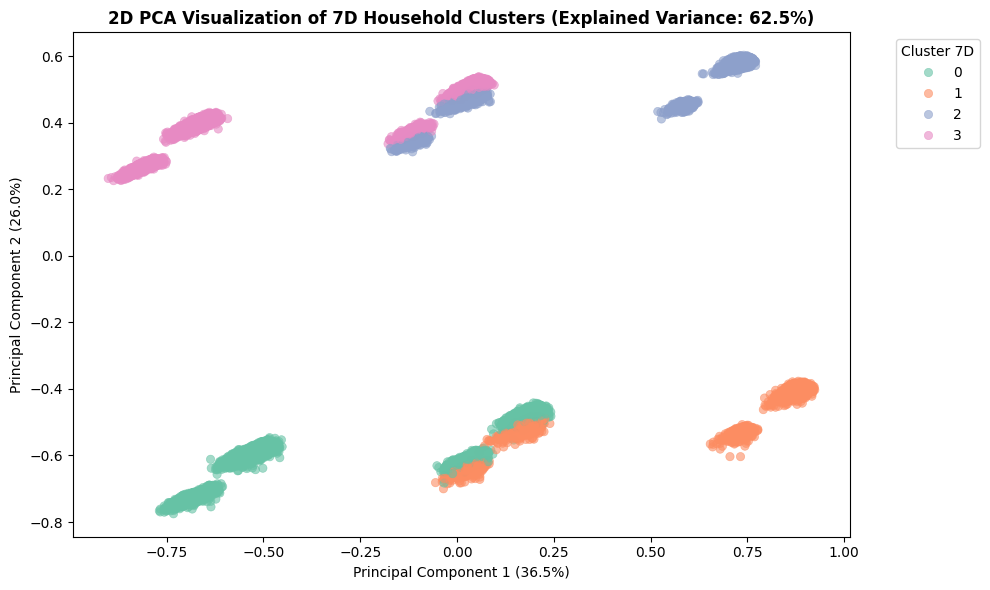

In [15]:

# 1. Apply PCA to reduce the 7D scaled dataset (X_scaled_7d) to 2 components
pca = PCA(n_components=2, random_state=42)
X_pca_7d = pca.fit_transform(X_scaled_7d)

# Store PCA coordinates back into the DataFrame
df_model_7d["pca_one"] = X_pca_7d[:, 0]
df_model_7d["pca_two"] = X_pca_7d[:, 1]

# Print total variance explained by the 2 principal components
explained_var = pca.explained_variance_ratio_.sum() * 100
print(f"Total Explained Variance (PC1 + PC2): {explained_var:.2f}%")

# 2. Plot 2D PCA Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="pca_one",
    y="pca_two",
    hue="cluster_7d",
    palette="Set2",
    data=df_model_7d,
    alpha=0.6,
    edgecolor=None,
)

plt.title(
    f"2D PCA Visualization of 7D Household Clusters (Explained Variance: {explained_var:.1f}%)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel(
    f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)
plt.legend(title="Cluster 7D", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()